# 07 · The dark-market closure — before and after time step 43

The test set of the project covers time steps 41–49. According to Weber et al. (*Anti-Money Laundering in Bitcoin: Experimenting with Graph Convolutional Networks for Financial Forensics*, 2019), a large dark market closes at time step 43, and the models stop finding illicit transactions from that point on. Step 05 reports one number for the whole test. This notebook splits that number in two and answers three questions:
1. **How well does each model do before and after the closure?** All 44 (menu, model) pairs.
2. **When exactly does it stop?** The recall time step by time step.
3. **Why?** Do the illicit transactions change after the closure?

**Runtime: CPU**, a few minutes. Nothing is trained: everything comes from the files of steps 02 and 04.

**Inputs** (on Drive): `02-feature-menus/config.json` and `dataset.parquet`; `04-final-runs/predictions/` and `summary/` of the 132 triples.

**Outputs:** tables in `07-market-closure/` (`period_counts.csv`, `closure_by_triple.csv`, `closure_summary.csv`, `recall_by_step.csv`, `illicit_profile.csv`, `illicit_shares.csv`) and plots `plots/07_*.png`.

**The two periods**, fixed in advance from the time step reported by Weber et al.: **before** = time steps 41–42, **after** = time steps 43–49. The models were all trained on time steps 1–30, so they never saw the closure. The threshold of each model is the one chosen on validation in step 04, unchanged.

**Measures, for each period.**
- **PR-AUC.** It depends on the prevalence, and the prevalence falls from 10.9% before to 2.6% after, so a lower PR-AUC after the closure is partly expected. The **lift** = PR-AUC / prevalence corrects for this: a random classifier has lift 1.
- **ROC-AUC**: the probability that a random illicit transaction gets a higher score than a random licit one. It does not depend on the prevalence, so it compares the two periods fairly. 0.5 = random. **Below 0.5 the model ranks illicit transactions under licit ones.**
- **Recall and precision** at the threshold chosen on validation: what the model would really flag.
- **Found in the top 524**: how many illicit transactions of the period are among the 524 highest scores of the whole test (524 = the illicit transactions of the test), as in step 05.

**Uncertainty.** As in step 05, one 95% interval counts both the test sample and the seeds (two-level bootstrap). Inside each period, 1,000 resamples of the rows are drawn, the same for every triple; at each resample three seeds are drawn at random with replacement and averaged. The result is compared with chance on the same resample: PR-AUC with the prevalence of the resample, ROC-AUC with 0.5.

## 0. Setup

In [1]:
# Connect Google Drive: every input and output of the project lives in DATA_PATH.
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')

DATA_PATH = Path('/content/drive/MyDrive/UNIVERSITA/block-crypto/data')
INPUT_DIR = DATA_PATH / '02-feature-menus'     # output of step 02
RUNS_DIR = DATA_PATH / '04-final-runs'         # output of step 04
OUT_DIR = DATA_PATH / '07-market-closure'      # tables of this notebook
PLOT_DIR = DATA_PATH / 'plots'                 # every plot of the project

Mounted at /content/drive


In [2]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, Normalize, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from PIL import Image
from sklearn.metrics import average_precision_score, roc_auc_score

FORCE_RECOMPUTE = False   # True = write again the tables and plots that are already on Drive
PERIODS = {'before': (41, 42), 'after': (43, 49)}
LOW, HIGH = 2.5, 97.5     # the 95% interval
DRAW_SEED = 0             # the draw of the seeds in the two-level bootstrap
OUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
# Colours of the report (as in steps 05 and 06). Classes: red and blue. Several series: the categorical slots.
# Magnitudes: one blue ramp. ROC-AUC: blue above 0.5, grey at 0.5, red below 0.5.
SURFACE, INK, INK_2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
ILLICIT, LICIT, VIOLET, ORANGE, AQUA, YELLOW = '#e34948', '#2a78d6', '#6250d6', '#eb6834', '#1baf7a', '#eda100'
BLUE_RAMP = ['#cde2fb', '#b7d3f6', '#9ec5f4', '#86b6ef', '#6da7ec', '#5598e7', '#3987e5', '#2a78d6', '#256abf',
             '#1c5cab', '#184f95', '#104281', '#0d366b']
BLUE_CMAP = LinearSegmentedColormap.from_list('blue', BLUE_RAMP)
ROC_CMAP = LinearSegmentedColormap.from_list('roc', ['#e34948', '#f4c0bf', '#eceae6', '#9ec5f4', '#0d366b'])
MODELS = ['logreg', 'rf', 'xgb', 'mlp', 'sage', 'gatv2', 'cheb', 'gin']
MODEL_NAME = {'logreg': 'LogReg', 'rf': 'Random Forest', 'xgb': 'XGBoost', 'mlp': 'MLP', 'sage': 'GraphSAGE',
              'gatv2': 'GATv2', 'cheb': 'ChebNet', 'gin': 'GIN'}
MENUS = ['local', 'graph', 'econ', 'none', 'local_agg', 'transparent', 'local_agg_graph']

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'text.color': INK, 'axes.labelcolor': INK_2, 'xtick.color': INK_2, 'ytick.color': INK_2,
    'axes.edgecolor': AXIS, 'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False,
})
MAX_PIXELS, MAX_KB = (1200, 800), 200


def atomic(path, write):
    tmp = path.with_name(path.name + '.tmp')
    write(tmp)
    os.replace(tmp, path)


def save_table(df, name):
    """Write a table to OUT_DIR, unless it is already there."""
    path = OUT_DIR / name
    if path.exists() and not FORCE_RECOMPUTE:
        print(f'{name} is already on Drive: not overwritten.')
    else:
        atomic(path, lambda tmp: df.to_csv(tmp, index=False, float_format='%.6g'))
        print(f'{name} written ({len(df):,} rows).')


def save_png(fig, name):
    """Show a figure and save it at 100 dpi: at most 1200 x 800 pixels and 200 KB
    (a 256-colour PNG if the full-colour one is too big). An existing plot is not overwritten."""
    width, height = fig.get_size_inches() * 100
    assert width <= MAX_PIXELS[0] + 0.5 and height <= MAX_PIXELS[1] + 0.5, 'figure too large'
    path = PLOT_DIR / name
    if path.exists() and not FORCE_RECOMPUTE:
        plt.show()
        plt.close(fig)
        print(f'{name} is already on Drive: not overwritten.')
        return
    tmp = path.with_name(path.name + '.tmp')
    fig.savefig(tmp, dpi=100, format='png')
    plt.show()
    plt.close(fig)
    if tmp.stat().st_size > MAX_KB * 1000:
        with Image.open(tmp) as image:
            small = image.convert('RGB').quantize(256)
        small.save(tmp, format='PNG', optimize=True)
    size = tmp.stat().st_size / 1000
    assert size <= MAX_KB, f'{name}: {size:.0f} KB'
    os.replace(tmp, path)
    print(f'{name} written ({size:.0f} KB).')


def titles(fig, title, subtitle, top=0.97):
    fig.text(0.02, top, title, fontsize=13, weight='bold', ha='left', va='top')
    fig.text(0.02, top - 0.045 * 8 / fig.get_size_inches()[1], subtitle, fontsize=9, color=INK_2,
             ha='left', va='top', linespacing=1.4)


def text_color_on(rgba):
    r, g, b = rgba[:3]
    return 'white' if 0.2126 * r + 0.7152 * g + 0.0722 * b < 0.5 else INK


def light_grid(ax, axis='y'):
    ax.grid(axis=axis, color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)

In [4]:
def triple_id(menu, model, seed):
    return f'{menu}__{model}__seed{seed}'


def bootstrap_weights(n, resamples, seed):
    """Copy of the function of step 04: how many times each row appears in each bootstrap resample."""
    rng = np.random.default_rng(seed)
    picks = rng.integers(0, n, size=(resamples, n))
    flat_picks = (picks + n * np.arange(resamples)[:, None]).ravel()
    return np.bincount(flat_picks, minlength=resamples * n).reshape(resamples, n).astype(np.int32)


def ap_roc(y, score, weights):
    """PR-AUC and ROC-AUC of one ranking on many resamples at once. y, score: n rows; weights: resamples x n.
    tp and fp are counted at the end of each group of equal scores, as scikit-learn does."""
    order = np.argsort(-score, kind='stable')
    last = np.r_[np.flatnonzero(np.diff(score[order])), len(y) - 1]
    w = weights[:, order]
    tp = np.cumsum(w * y[order], axis=1)[:, last]
    fp = np.cumsum(w * (1 - y[order]), axis=1)[:, last]
    positives, negatives = tp[:, -1:], fp[:, -1:]
    flagged = tp + fp
    precision = np.divide(tp, flagged, out=np.zeros(tp.shape), where=flagged > 0)
    ap = (np.diff(tp, axis=1, prepend=0) / positives * precision).sum(axis=1)
    tp_before = np.c_[np.zeros(len(tp)), tp[:, :-1]]
    roc = (np.diff(fp, axis=1, prepend=0) * (tp + tp_before) / 2).sum(axis=1) / (positives * negatives)[:, 0]
    return ap, roc


def two_level(values, seed=DRAW_SEED):
    """Two-level bootstrap, as in step 05: values are (seeds x resamples). At every resample, the seeds are drawn at
    random with replacement and averaged; the result is one value per resample."""
    rng = np.random.default_rng(seed)
    columns = np.arange(values.shape[1])[:, None]
    picks = rng.integers(0, values.shape[0], size=(values.shape[1], values.shape[0]))
    return values[picks, columns].mean(axis=1)


def against_chance(deltas):
    low, high = np.percentile(deltas, [LOW, HIGH])
    return 'above' if low > 0 else 'below' if high < 0 else 'not clear'


def ks_distance(a, b):
    """Kolmogorov-Smirnov distance: the largest gap between the two cumulative distributions (0 = same, 1 = apart)."""
    a, b = np.sort(a[np.isfinite(a)]), np.sort(b[np.isfinite(b)])
    grid = np.r_[a, b]
    return float(np.abs(np.searchsorted(a, grid, side='right') / len(a) - np.searchsorted(b, grid, side='right') / len(b)).max())

## 1. Toy tests

Before touching the real files: `ap_roc` with weights 1 and with resampling weights must equal scikit-learn, also with tied scores; a weight of 2 must equal the row written twice; the two-level bootstrap with identical seeds must change nothing; the Kolmogorov-Smirnov distance is checked on cases solved by hand.

In [5]:
rng = np.random.default_rng(0)
y_toy = (rng.random(400) < 0.2).astype(int)
for score_toy in [rng.random(400) + y_toy * 0.3, np.round(rng.random(400) + y_toy * 0.3, 1)]:   # the second one has ties
    ap, roc = ap_roc(y_toy, score_toy, np.ones((1, 400), dtype=np.int32))
    assert abs(ap[0] - average_precision_score(y_toy, score_toy)) < 1e-12
    assert abs(roc[0] - roc_auc_score(y_toy, score_toy)) < 1e-12
    weights_toy = bootstrap_weights(400, 5, 1)
    ap, roc = ap_roc(y_toy, score_toy, weights_toy)
    for b in range(5):
        assert abs(ap[b] - average_precision_score(y_toy, score_toy, sample_weight=weights_toy[b])) < 1e-12
        assert abs(roc[b] - roc_auc_score(y_toy, score_toy, sample_weight=weights_toy[b])) < 1e-12
double = np.r_[np.arange(400), 7]
ap, roc = ap_roc(y_toy, score_toy, (np.ones(400, dtype=np.int32) + (np.arange(400) == 7))[None])
assert abs(ap[0] - average_precision_score(y_toy[double], score_toy[double])) < 1e-12
assert abs(roc[0] - roc_auc_score(y_toy[double], score_toy[double])) < 1e-12
same = 0.5 + 0.1 * rng.standard_normal(100)
assert np.allclose(two_level(np.vstack([same] * 3)), same)
assert against_chance(np.full(10, 0.1)) == 'above' and against_chance(np.full(10, -0.1)) == 'below'
assert against_chance(np.linspace(-1, 1, 11)) == 'not clear'
assert ks_distance(np.array([1., 2.]), np.array([1., 2.])) == 0
assert ks_distance(np.array([1., 2.]), np.array([3., 4.])) == 1
assert ks_distance(np.array([1., 2., 3., 4.]), np.array([3., 4., 5., 6.])) == 0.5
assert ks_distance(np.array([1., np.nan]), np.array([1.])) == 0
print('Toy tests passed: PR-AUC and ROC-AUC on resamples, two-level bootstrap, Kolmogorov-Smirnov distance.')

Toy tests passed: PR-AUC and ROC-AUC on resamples, two-level bootstrap, Kolmogorov-Smirnov distance.


## 2. Load the saved scores

The notebook stops if a triple is missing, if the test rows differ between triples, or if the PR-AUC recomputed on the whole test differs from the one saved by step 04.

In [6]:
config = json.loads((INPUT_DIR / 'config.json').read_text(encoding='utf-8'))
PAIRS = [tuple(p) for p in config['pairs']]
SEEDS = config['final_runs']['seeds']
boot_cfg = config['evaluation']['bootstrap']
TRIPLES = [(menu, model, seed) for menu, model in PAIRS for seed in SEEDS]

RECORDS, SCORES = {}, {}
TEST = None
for menu, model, seed in TRIPLES:
    tid = triple_id(menu, model, seed)
    RECORDS[(menu, model, seed)] = json.loads((RUNS_DIR / 'summary' / f'{tid}.json').read_text(encoding='utf-8'))
    table = pd.read_parquet(RUNS_DIR / 'predictions' / f'{tid}.parquet', columns=['row', 'time_step', 'split', 'y', 'score'])
    table = table[table['split'] == 'test']
    if TEST is None:
        TEST = table[['row', 'time_step', 'y']].reset_index(drop=True)
    assert np.array_equal(table['row'].to_numpy(), TEST['row'].to_numpy()), f'{tid}: the rows of the test differ'
    SCORES[(menu, model, seed)] = table['score'].to_numpy(np.float64)
    saved = RECORDS[(menu, model, seed)]['metrics']['by_split']['test']['average_precision']
    assert abs(average_precision_score(TEST['y'].astype(int), SCORES[(menu, model, seed)]) - saved) < 1e-9, tid
Y = TEST['y'].to_numpy().astype(int)
STEP = TEST['time_step'].to_numpy().astype(int)
MASK = {name: (STEP >= a) & (STEP <= b) for name, (a, b) in PERIODS.items()}
assert (MASK['before'] | MASK['after']).all()
print(f'{len(TRIPLES)} triples loaded; PR-AUC of the whole test equal to step 04 in all of them.')

steps = np.arange(41, 50)
counts = pd.DataFrame({'time_step': steps, 'period': ['before' if s <= 42 else 'after' for s in steps],
                       'illicit': [int(Y[STEP == s].sum()) for s in steps],
                       'licit': [int((Y[STEP == s] == 0).sum()) for s in steps]})
counts['prevalence'] = counts['illicit'] / (counts['illicit'] + counts['licit'])
display(counts.round(4))
save_table(counts, 'period_counts.csv')
PREVALENCE = {name: float(Y[m].mean()) for name, m in MASK.items()}
print('Illicit:', {name: int(Y[m].sum()) for name, m in MASK.items()}, '| prevalence:', {k: round(v, 4) for k, v in PREVALENCE.items()})

132 triples loaded; PR-AUC of the whole test equal to step 04 in all of them.


,time_step,period,illicit,licit,prevalence
0,41,before,116,1011,0.1029
1,42,before,239,1903,0.1116
2,43,after,24,1303,0.0181
3,44,after,24,1554,0.0152
4,45,after,5,1193,0.0042
5,46,after,2,709,0.0028
6,47,after,22,814,0.0263
7,48,after,36,435,0.0764
8,49,after,56,420,0.1176


period_counts.csv written (9 rows).
Illicit: {'before': 355, 'after': 169} | prevalence: {'before': 0.1086, 'after': 0.0256}


## 3. Every model, before and after

`closure_by_triple.csv` has one row per triple and period. `closure_summary.csv` has one row per (menu, model) pair and period: mean and standard deviation over the seeds, the 95% interval of PR-AUC and ROC-AUC, and whether each one is clearly above or below chance.

In [7]:
WEIGHTS = {name: bootstrap_weights(int(m.sum()), boot_cfg['resamples'], boot_cfg['seed'] + k)
           for k, (name, m) in enumerate(MASK.items())}
CHANCE = {name: WEIGHTS[name] @ Y[m] / WEIGHTS[name].sum(axis=1) for name, m in MASK.items()}
K = int(Y.sum())
rows, resampled = [], {}
for (menu, model, seed), score in SCORES.items():
    threshold = RECORDS[(menu, model, seed)]['metrics']['thresholds']['best_val_f1']
    top = np.argsort(-score, kind='stable')[:K]
    in_top = np.zeros(len(Y), dtype=bool)
    in_top[top] = True
    for name, m in MASK.items():
        y, s = Y[m], score[m]
        ap, roc = ap_roc(y, s, np.ones((1, len(y)), dtype=np.int32))
        flagged = s >= threshold
        hits = int((flagged & (y == 1)).sum())
        rows.append({'menu': menu, 'model': model, 'seed': seed, 'period': name, 'pr_auc': ap[0], 'roc_auc': roc[0],
                     'recall': hits / y.sum(), 'precision': hits / flagged.sum() if flagged.any() else np.nan,
                     'flagged': int(flagged.sum()), 'found_in_top': int((in_top[m] & (Y[m] == 1)).sum()),
                     'illicit': int(y.sum()), 'rows': len(y)})
        resampled[(menu, model, seed, name)] = ap_roc(y, s, WEIGHTS[name])
BY_TRIPLE = pd.DataFrame(rows)
save_table(BY_TRIPLE, 'closure_by_triple.csv')

rows = []
for (menu, model), group in BY_TRIPLE.groupby(['menu', 'model'], sort=False):
    for name, g in group.groupby('period', sort=False):
        ap_b = two_level(np.vstack([resampled[(menu, model, s, name)][0] for s in SEEDS]))
        roc_b = two_level(np.vstack([resampled[(menu, model, s, name)][1] for s in SEEDS]))
        rows.append({'menu': menu, 'model': model, 'period': name, 'prevalence': PREVALENCE[name],
                     'pr_auc_mean': g['pr_auc'].mean(), 'pr_auc_std': g['pr_auc'].std(),
                     'pr_auc_low': np.percentile(ap_b, LOW), 'pr_auc_high': np.percentile(ap_b, HIGH),
                     'lift': g['pr_auc'].mean() / PREVALENCE[name], 'pr_auc_vs_chance': against_chance(ap_b - CHANCE[name]),
                     'roc_auc_mean': g['roc_auc'].mean(), 'roc_auc_std': g['roc_auc'].std(),
                     'roc_auc_low': np.percentile(roc_b, LOW), 'roc_auc_high': np.percentile(roc_b, HIGH),
                     'roc_auc_vs_chance': against_chance(roc_b - 0.5),
                     'recall_mean': g['recall'].mean(), 'precision_mean': g['precision'].mean(),
                     'flagged_mean': g['flagged'].mean(), 'found_in_top_mean': g['found_in_top'].mean()})
SUMMARY = pd.DataFrame(rows)
save_table(SUMMARY, 'closure_summary.csv')
display(SUMMARY.pivot_table(index=['menu', 'model'], columns='period', values=['pr_auc_mean', 'roc_auc_mean', 'found_in_top_mean'])
        .round(3).loc[[p for p in PAIRS if p[1] in ('xgb', 'gatv2', 'cheb', 'gin')]])

closure_by_triple.csv written (264 rows).
closure_summary.csv written (88 rows).


found_in_top_mean          pr_auc_mean         \
period                            after   before       after before   
menu            model                                                 
local           xgb               5.000  296.333       0.037  0.905   
local_agg       xgb               4.667  305.000       0.041  0.914   
graph           xgb               3.667  103.000       0.027  0.464   
econ            xgb              11.333  260.333       0.023  0.777   
transparent     xgb               8.000  260.333       0.022  0.789   
local_agg_graph xgb               5.333  303.667       0.042  0.914   
local           gatv2             1.667  236.000       0.030  0.780   
local_agg       gatv2             4.000  257.667       0.040  0.762   
graph           gatv2            36.333  122.667       0.107  0.525   
econ            gatv2             1.667  277.667       0.017  0.795   
transparent     gatv2             0.333  226.333       0.026  0.778   
local_agg_graph gatv2             3.000  250.000       0.034  0.765   
local           cheb              2.000  280.333       0.042  0.849   
local_agg       cheb              3.333  260.667       0.051  0.759   
graph           cheb              7.667  120.667       0.049  0.489   
econ            cheb              1.333  252.333       0.033  0.806   
transparent     cheb              2.000  224.333       0.035  0.759   
local_agg_graph cheb              4.667  238.000       0.050  0.695   
none            cheb              5.000   97.333       0.025  0.490   
                gin               4.667  112.000       0.029  0.492   

                      roc_auc_mean         
period                       after before  
menu            model                      
local           xgb          0.642  0.970  
local_agg       xgb          0.701  0.970  
graph           xgb          0.524  0.847  
econ            xgb          0.374  0.912  
transparent     xgb          0.404  0.917  
local_agg_graph xgb          0.703  0.970  
local           gatv2        0.609  0.923  
local_agg       gatv2        0.699  0.931  
graph           gatv2        0.748  0.818  
econ            gatv2        0.286  0.898  
transparent     gatv2        0.545  0.927  
local_agg_graph gatv2        0.619  0.925  
local           cheb         0.722  0.946  
local_agg       cheb         0.717  0.938  
graph           cheb         0.677  0.787  
econ            cheb         0.640  0.954  
transparent     cheb         0.637  0.946  
local_agg_graph cheb         0.710  0.923  
none            cheb         0.454  0.839  
                gin          0.503  0.826

## 4. Plot 1 — every model before and after (`07_before_after.png`)

Rows: models; columns: menus; each cell is the mean over the 3 seeds. On the left the PR-AUC, with the same scale in the two maps, so that the fall can be seen; remember that the prevalence falls too. On the right the ROC-AUC, which does not depend on the prevalence: grey is 0.5 (random), blue is above it, red is below it. A red cell means that the model puts illicit transactions **under** licit ones.

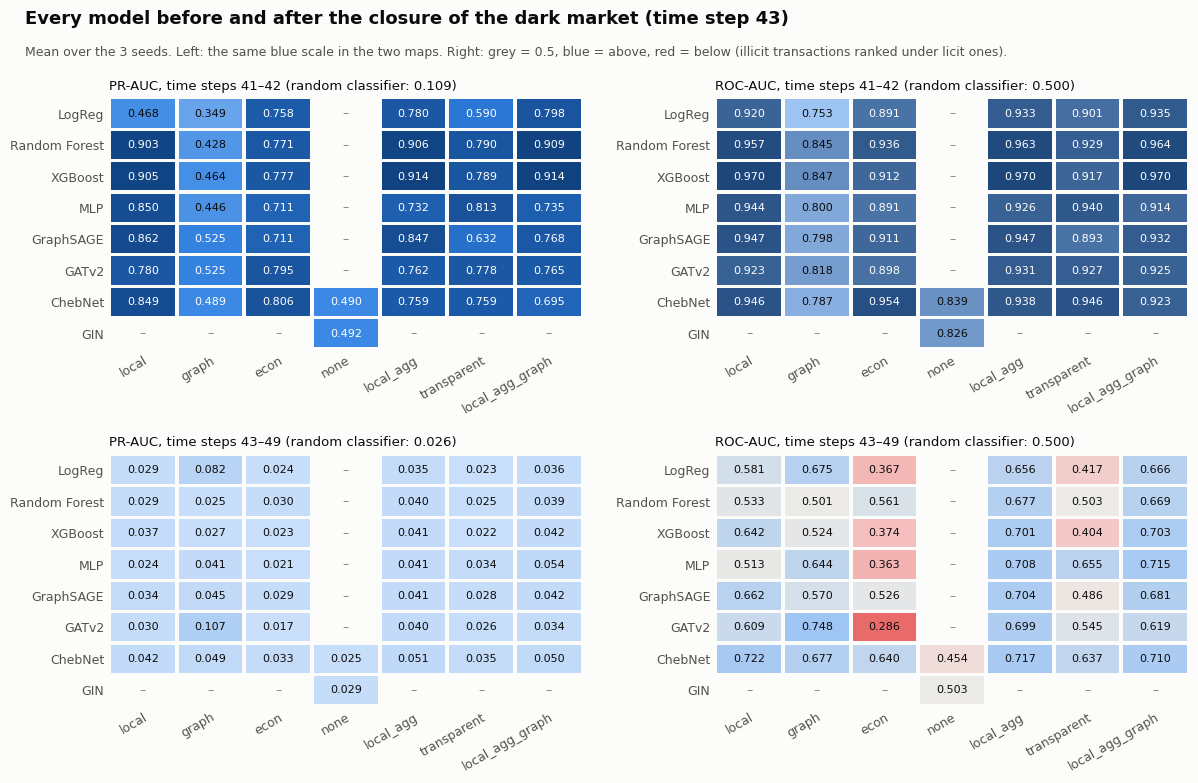

07_before_after.png written (184 KB).


In [8]:
def heatmap(ax, values, norm, cmap, row_labels, col_labels, fmt='{:.3f}'):
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            if not np.isfinite(values[i, j]):
                ax.text(j + 0.5, i + 0.5, '–', ha='center', va='center', color=MUTED)
                continue
            color = cmap(norm(values[i, j]))
            ax.add_patch(Rectangle((j + 0.03, i + 0.05), 0.94, 0.9, facecolor=color, edgecolor='none'))
            ax.text(j + 0.5, i + 0.5, fmt.format(values[i, j]), ha='center', va='center', fontsize=8, color=text_color_on(color))
    ax.set_xlim(0, values.shape[1])
    ax.set_ylim(values.shape[0], 0)
    ax.set_xticks(np.arange(values.shape[1]) + 0.5, col_labels, rotation=30, ha='right', rotation_mode='anchor')
    ax.set_yticks(np.arange(values.shape[0]) + 0.5, row_labels)
    ax.tick_params(length=0)
    for side in ['left', 'bottom']:
        ax.spines[side].set_visible(False)


def table_of(period, column):
    sel = SUMMARY[SUMMARY['period'] == period].pivot(index='model', columns='menu', values=column)
    return sel.reindex(index=MODELS, columns=MENUS).to_numpy(dtype=np.float64)


fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.subplots_adjust(left=0.09, right=0.99, top=0.86, bottom=0.1, wspace=0.28, hspace=0.42)
names = [MODEL_NAME[m] for m in MODELS]
ap_norm, roc_norm = Normalize(0, 1), TwoSlopeNorm(vmin=0.25, vcenter=0.5, vmax=1.0)
for row, period in enumerate(['before', 'after']):
    a, b = PERIODS[period]
    heatmap(axes[row, 0], table_of(period, 'pr_auc_mean'), ap_norm, BLUE_CMAP, names, MENUS)
    axes[row, 0].set_title(f'PR-AUC, time steps {a}–{b} (random classifier: {PREVALENCE[period]:.3f})', fontsize=9.5, loc='left')
    heatmap(axes[row, 1], table_of(period, 'roc_auc_mean'), roc_norm, ROC_CMAP, names, MENUS)
    axes[row, 1].set_title(f'ROC-AUC, time steps {a}–{b} (random classifier: 0.500)', fontsize=9.5, loc='left')
titles(fig, 'Every model before and after the closure of the dark market (time step 43)',
       'Mean over the 3 seeds. Left: the same blue scale in the two maps. Right: grey = 0.5, blue = above, red = below '
       '(illicit transactions ranked under licit ones).')
save_png(fig, '07_before_after.png')

## 5. Plot 2 — time step by time step (`07_recall_by_step.png`)

Top: the illicit transactions of each time step of the test. Bottom: the share of them that the model flags at its validation threshold (recall), mean over the 3 seeds, for four menus with the model chosen on validation for that menu, as in step 05. After the closure a time step has few illicit transactions (2 in time step 46), so a single point moves a lot: look at the whole period, one point at a time says little. `recall_by_step.csv` has every pair.

recall_by_step.csv written (396 rows).
Model chosen on validation, per menu: {'local': 'xgb', 'graph': 'sage', 'econ': 'xgb', 'none': 'cheb', 'local_agg': 'xgb', 'transparent': 'xgb', 'local_agg_graph': 'xgb'}


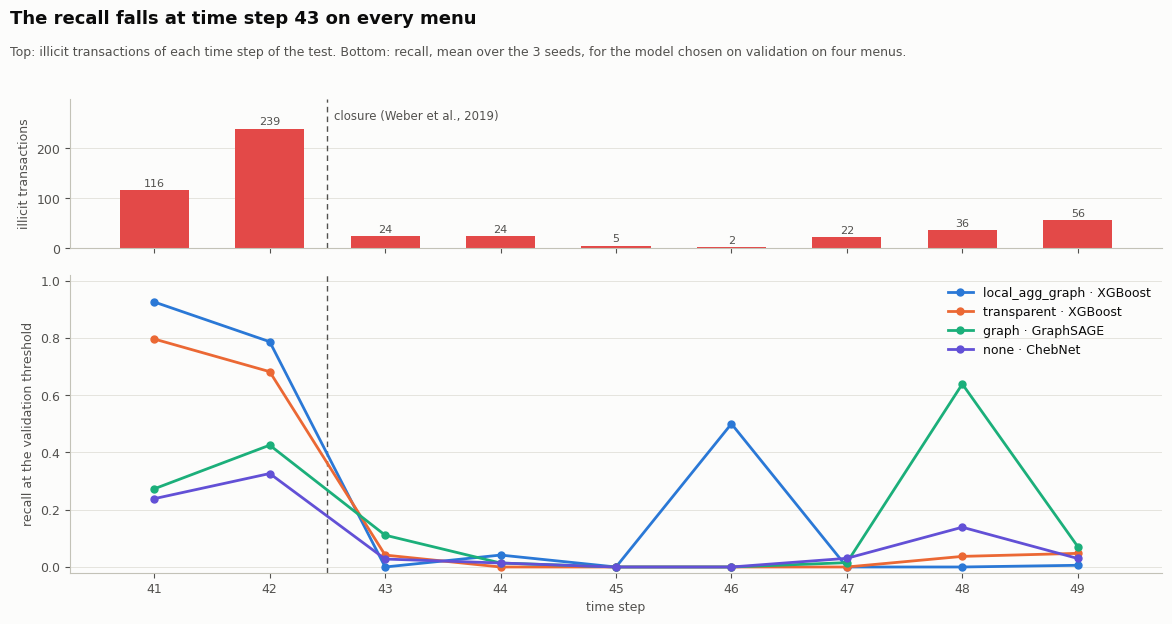

07_recall_by_step.png written (95 KB).


In [9]:
rows = []
for (menu, model, seed), score in SCORES.items():
    flagged = score >= RECORDS[(menu, model, seed)]['metrics']['thresholds']['best_val_f1']
    for s in steps:
        illicit = (STEP == s) & (Y == 1)
        rows.append({'menu': menu, 'model': model, 'seed': seed, 'time_step': int(s), 'recall': flagged[illicit].mean()})
BY_STEP = pd.DataFrame(rows)
step_mean = BY_STEP.groupby(['menu', 'model', 'time_step'])['recall'].agg(['mean', 'std']).reset_index()
save_table(step_mean, 'recall_by_step.csv')

CHOSEN = {}
for menu in MENUS:
    models = [mo for m, mo in PAIRS if m == menu]
    CHOSEN[menu] = max(models, key=lambda mo: np.mean([RECORDS[(menu, mo, s)]['metrics']['by_split']['val']['average_precision'] for s in SEEDS]))
print('Model chosen on validation, per menu:', CHOSEN)

fig, (top, bottom) = plt.subplots(2, 1, figsize=(12, 6.4), sharex=True, gridspec_kw={'height_ratios': [1, 2]})
fig.subplots_adjust(left=0.07, right=0.98, top=0.83, bottom=0.09, hspace=0.12)
top.bar(counts['time_step'], counts['illicit'], width=0.6, color=ILLICIT, zorder=2)
for s, n in zip(counts['time_step'], counts['illicit']):
    top.text(s, n + 4, str(n), ha='center', va='bottom', fontsize=8, color=INK_2)
top.set_ylabel('illicit transactions')
top.set_ylim(0, counts['illicit'].max() * 1.25)
light_grid(top)
series = [('local_agg_graph', LICIT, '-'), ('transparent', ORANGE, '-'), ('graph', AQUA, '-'), ('none', VIOLET, '-')]
for menu, color, style in series:
    sel = step_mean[(step_mean['menu'] == menu) & (step_mean['model'] == CHOSEN[menu])]
    bottom.plot(sel['time_step'], sel['mean'], color=color, linestyle=style, linewidth=2, marker='o', markersize=5,
                label=f'{menu} · {MODEL_NAME[CHOSEN[menu]]}', zorder=3)
bottom.set_ylabel('recall at the validation threshold')
bottom.set_xlabel('time step')
bottom.set_xticks(steps)
bottom.set_ylim(-0.02, 1.02)
light_grid(bottom)
bottom.legend(frameon=False, fontsize=9, loc='upper right')
for ax in (top, bottom):
    ax.axvline(42.5, color=INK_2, linewidth=1, linestyle=(0, (4, 3)), zorder=1)
top.text(42.56, top.get_ylim()[1] * 0.93, 'closure (Weber et al., 2019)', fontsize=8.5, color=INK_2, va='top')
titles(fig, 'The recall falls at time step 43 on every menu',
       'Top: illicit transactions of each time step of the test. Bottom: recall, mean over the 3 seeds, for the model chosen '
       'on validation on four menus.')
save_png(fig, '07_recall_by_step.png')

## 6. Plot 3 — did the illicit transactions change? (`07_illicit_profile.png`)

The models learned on time steps 1–30. If the illicit transactions after the closure look different from those, the rules learned no longer apply. For the 33 columns of `transparent` (raw values, evaluation rows), four groups: illicit of the train, illicit before the closure, illicit after the closure, licit after the closure. `illicit_profile.csv` has the median of each column in each group and three **Kolmogorov-Smirnov distances** (0 = same distribution, 1 = completely apart), and `illicit_shares.csv` the share of each group that satisfies three simple rules.

The plot shows the cumulative distribution (share of transactions with a value up to $x$) of the three columns XGBoost relies on most on `transparent` (step 06: `size`, `num_input_addresses`, `num_output_addresses`) and of the structural column that best separates illicit from licit after the closure. If the yellow curve moves away from the red and grey ones, the illicit transactions changed; if it also moves past the blue one, on that column they now sit on the far side of the licit ones, and a model that learned the old rule ranks them low.

{'illicit, train': 2954, 'illicit, before': 355, 'illicit, after': 169, 'licit, after': 6428}
illicit_profile.csv written (33 rows).


,ks_illicit_train_vs_before,ks_illicit_train_vs_after,ks_illicit_vs_licit_after
family,,,
A,0.151,0.345,0.291
B,0.254,0.372,0.256
C,0.047,0.142,0.105
D,0.345,0.589,0.312


,column,family,"median illicit, train","median illicit, before","median illicit, after","median licit, after",ks_illicit_train_vs_after,ks_illicit_train_vs_before,ks_illicit_vs_licit_after
26,size,D,192.000,192.000,667.000,372.000,0.811,0.083,0.364
27,num_input_addresses,D,1.000,1.000,4.000,1.000,0.801,0.015,0.422
25,fees,D,0.000,0.001,0.001,0.001,0.763,0.949,0.164
29,in_BTC_min,D,0.142,0.030,0.005,0.037,0.718,0.400,0.474
16,clo,B,0.075,0.123,0.102,0.118,0.716,0.751,0.203
31,out_BTC_min,D,0.070,0.022,0.010,0.010,0.633,0.356,0.328
28,num_output_addresses,D,1.000,1.000,2.000,2.000,0.627,0.064,0.174
11,eig,B,0.000,0.000,0.001,0.001,0.598,0.396,0.192


illicit_shares.csv written (3 rows).


,rule,"illicit, train","illicit, before","illicit, after","licit, after"
0,size < 200 bytes,0.657,0.732,0.000,0.008
1,1 input address,0.919,0.910,0.118,0.539
2,1 output address,0.668,0.732,0.041,0.021


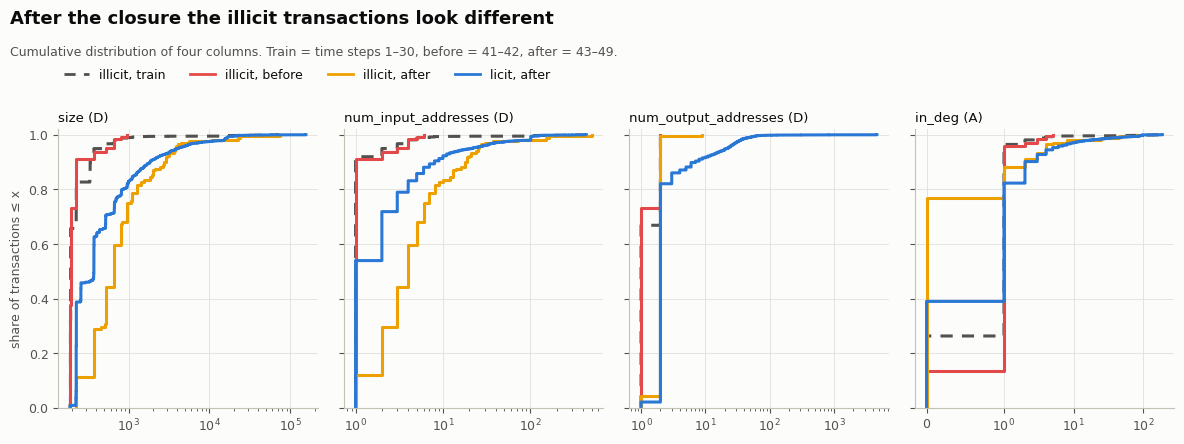

07_illicit_profile.png written (52 KB).


In [10]:
columns = config['menus']['transparent']['columns']
family = {c: f for f in 'ABCD' for c in config['columns']['families'][f]['kept']}
raw = pd.read_parquet(INPUT_DIR / 'dataset.parquet', columns=columns + ['time_step', 'y', 'in_eval'])
y_all = raw['y'].to_numpy(dtype=np.float64, na_value=np.nan)
step_all, in_eval = raw['time_step'].to_numpy().astype(int), raw['in_eval'].to_numpy().astype(bool)
GROUPS = {'illicit, train': in_eval & (y_all == 1) & (step_all <= 30),
          'illicit, before': in_eval & (y_all == 1) & (step_all >= 41) & (step_all <= 42),
          'illicit, after': in_eval & (y_all == 1) & (step_all >= 43),
          'licit, after': in_eval & (y_all == 0) & (step_all >= 43)}
GROUP_STYLE = {'illicit, train': (INK_2, (0, (4, 3))), 'illicit, before': (ILLICIT, '-'), 'illicit, after': (YELLOW, '-'), 'licit, after': (LICIT, '-')}
print({name: int(g.sum()) for name, g in GROUPS.items()})
assert GROUPS['illicit, before'].sum() == Y[MASK['before']].sum() and GROUPS['illicit, after'].sum() == Y[MASK['after']].sum()

rows = []
for c in columns:
    v = raw[c].to_numpy(dtype=np.float64)
    rows.append({'column': c, 'family': family[c], **{f'median {name}': float(np.nanmedian(v[g])) for name, g in GROUPS.items()},
                 'ks_illicit_train_vs_after': ks_distance(v[GROUPS['illicit, train']], v[GROUPS['illicit, after']]),
                 'ks_illicit_train_vs_before': ks_distance(v[GROUPS['illicit, train']], v[GROUPS['illicit, before']]),
                 'ks_illicit_vs_licit_after': ks_distance(v[GROUPS['illicit, after']], v[GROUPS['licit, after']])})
PROFILE = pd.DataFrame(rows)
save_table(PROFILE, 'illicit_profile.csv')
display(PROFILE.groupby('family')[['ks_illicit_train_vs_before', 'ks_illicit_train_vs_after', 'ks_illicit_vs_licit_after']].mean().round(3))
display(PROFILE.sort_values('ks_illicit_train_vs_after', ascending=False).head(8).round(3))

RULES = {'size < 200 bytes': raw['size'].to_numpy() < 200, '1 input address': raw['num_input_addresses'].to_numpy() == 1,
         '1 output address': raw['num_output_addresses'].to_numpy() == 1}
SHARES = pd.DataFrame([{'rule': rule, **{name: float(hit[g].mean()) for name, g in GROUPS.items()}} for rule, hit in RULES.items()])
save_table(SHARES, 'illicit_shares.csv')
display(SHARES.round(3))

structure = PROFILE[PROFILE['family'] != 'D'].sort_values('ks_illicit_vs_licit_after', ascending=False, kind='stable')['column'].iloc[0]
shown = ['size', 'num_input_addresses', 'num_output_addresses', structure]
fig, axes = plt.subplots(1, 4, figsize=(12, 4.8), sharey=True)
fig.subplots_adjust(left=0.06, right=0.99, top=0.72, bottom=0.14, wspace=0.1)
for ax, c in zip(axes, shown):
    v = raw[c].to_numpy(dtype=np.float64)
    for name, g in GROUPS.items():
        x = np.sort(v[g][np.isfinite(v[g])])
        color, style = GROUP_STYLE[name]
        ax.step(x, np.arange(1, len(x) + 1) / len(x), where='post', color=color, linestyle=style, linewidth=2.2)
    if np.nanmin(v[np.any(list(GROUPS.values()), axis=0)]) > 0:
        ax.set_xscale('log')
    else:
        ax.set_xscale('symlog', linthresh=1)
    ax.set_title(f'{c} ({family[c]})', fontsize=9.5, loc='left')
    ax.set_ylim(0, 1.02)
    light_grid(ax, 'both')
axes[0].set_ylabel('share of transactions ≤ x')
fig.legend(handles=[Line2D([], [], color=GROUP_STYLE[n][0], linestyle=GROUP_STYLE[n][1], linewidth=2, label=n) for n in GROUPS],
           loc='upper left', bbox_to_anchor=(0.055, 0.87), ncol=4, frameon=False, fontsize=9)
titles(fig, 'After the closure the illicit transactions look different',
       'Cumulative distribution of four columns. Train = time steps 1–30, before = 41–42, after = 43–49.')
save_png(fig, '07_illicit_profile.png')

## 7. The results in numbers, and the files written

Everything below is computed from the tables above.

In [11]:
s = SUMMARY.set_index(['menu', 'model', 'period'])
ref = ('local_agg_graph', 'xgb')
print(f"{ref[0]} · XGBoost: PR-AUC {s.loc[(*ref, 'before'), 'pr_auc_mean']:.3f} before, {s.loc[(*ref, 'after'), 'pr_auc_mean']:.3f} after; "
      f"ROC-AUC {s.loc[(*ref, 'before'), 'roc_auc_mean']:.3f} before, {s.loc[(*ref, 'after'), 'roc_auc_mean']:.3f} after.")
after = SUMMARY[SUMMARY['period'] == 'after']
print(f"After the closure, of {len(after)} pairs: ROC-AUC clearly below 0.5 in {(after['roc_auc_vs_chance'] == 'below').sum()}, "
      f"clearly above in {(after['roc_auc_vs_chance'] == 'above').sum()}; PR-AUC clearly above chance in {(after['pr_auc_vs_chance'] == 'above').sum()}.")
print('ROC-AUC clearly below 0.5 after the closure:',
      [f'{r.menu} · {MODEL_NAME[r.model]}' for r in after[after['roc_auc_vs_chance'] == 'below'].itertuples()])
print('\nHighest lift after the closure:')
display(after.sort_values('lift', ascending=False).head(6)[['menu', 'model', 'pr_auc_mean', 'pr_auc_std', 'pr_auc_low', 'pr_auc_high', 'lift',
                                                           'roc_auc_mean', 'roc_auc_low', 'roc_auc_high', 'recall_mean', 'found_in_top_mean']].round(3))
print('Files:')
for path in sorted(OUT_DIR.glob('*.csv')):
    print(f'{path.name:28s} {path.stat().st_size / 1e3:8.1f} KB')
for path in sorted(PLOT_DIR.glob('07_*.png')):
    print(f'{path.name:28s} {path.stat().st_size / 1e3:8.1f} KB')
drive.flush_and_unmount()

local_agg_graph · XGBoost: PR-AUC 0.914 before, 0.042 after; ROC-AUC 0.970 before, 0.703 after.
After the closure, of 44 pairs: ROC-AUC clearly below 0.5 in 7, clearly above in 28; PR-AUC clearly above chance in 28.
ROC-AUC clearly below 0.5 after the closure: ['econ · LogReg', 'transparent · LogReg', 'econ · XGBoost', 'transparent · XGBoost', 'econ · MLP', 'econ · GATv2', 'none · ChebNet']

Highest lift after the closure:


,menu,model,pr_auc_mean,pr_auc_std,pr_auc_low,pr_auc_high,lift,roc_auc_mean,roc_auc_low,roc_auc_high,recall_mean,found_in_top_mean
65,graph,gatv2,0.107,0.062,0.049,0.176,4.183,0.748,0.694,0.800,0.213,36.333
5,graph,logreg,0.082,0.000,0.062,0.107,3.203,0.675,0.632,0.721,0.456,50.000
47,local_agg_graph,mlp,0.054,0.006,0.038,0.080,2.092,0.715,0.693,0.738,0.041,7.667
75,local_agg,cheb,0.051,0.005,0.038,0.073,1.990,0.717,0.686,0.747,0.018,3.333
83,local_agg_graph,cheb,0.050,0.008,0.037,0.071,1.941,0.710,0.669,0.757,0.016,4.667
77,graph,cheb,0.049,0.004,0.040,0.062,1.930,0.677,0.640,0.714,0.045,7.667


Files:
closure_by_triple.csv            19.7 KB
closure_summary.csv              13.9 KB
illicit_profile.csv               2.1 KB
illicit_shares.csv                0.2 KB
period_counts.csv                 0.3 KB
recall_by_step.csv               10.8 KB
07_before_after.png             184.2 KB
07_illicit_profile.png           51.8 KB
07_recall_by_step.png            95.0 KB
